541.0 949.0 984 20.64 16728


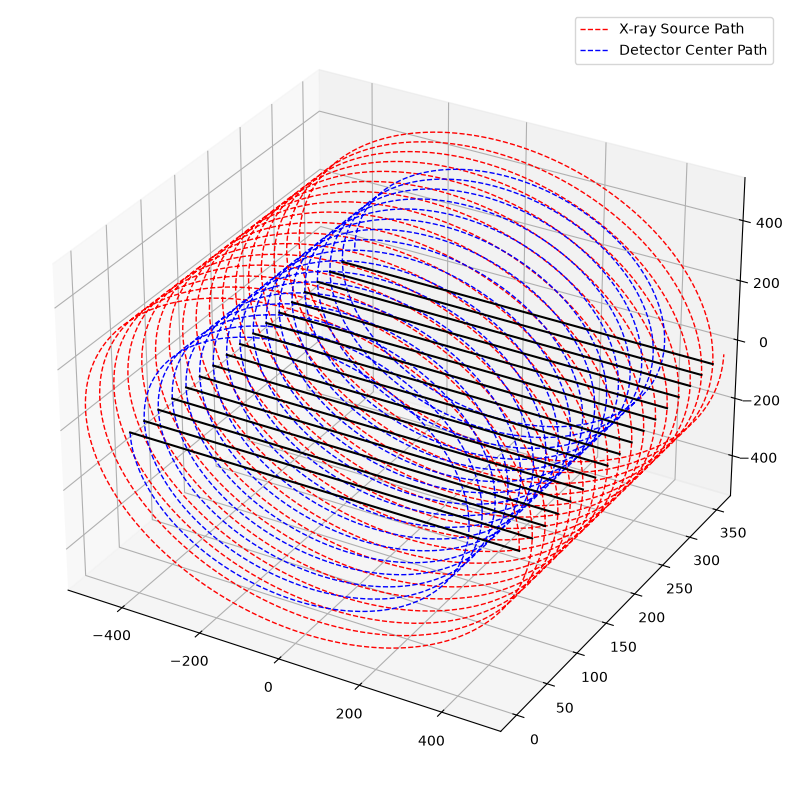

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import json

def plot_source_and_detector_kinematics(config_file="ct_config_by_team.json"):
    with open(config_file, "r") as file:
        config = json.load(file)
        
    system_config = config.get("4_system_config_team", {})
    sid = system_config.get("sid_mm")
    sdd = system_config.get("sdd_mm")
    views_per_rotation = system_config.get("num_views_per_rotation")
    table_feed_per_rot = system_config.get("table_feed_per_rotation_mm")
    total_views = system_config.get("total_views")
    print(sid, sdd, views_per_rotation, table_feed_per_rot, total_views)
    source_radius = sid
    detector_radius = sdd - sid
    
    views = np.arange(total_views)

    y_shift = table_feed_per_rot / views_per_rotation
    y_coords = views * y_shift
    angle_per_view = (np.pi * 2) / views_per_rotation
    theta = views * angle_per_view
 
    x_source = source_radius * np.cos(theta)
    z_source = source_radius * np.sin(theta)

    x_detector = -detector_radius * np.cos(theta)
    z_detector = -detector_radius * np.sin(theta)
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    ax.plot(x_source, y_coords, z_source, label='X-ray Source Path', color='red', linewidth=1.0, linestyle='--')
    ax.plot(x_detector, y_coords, z_detector, label='Detector Center Path', color='blue', linewidth=1.0, linestyle='--')
    
    sample_interval = views_per_rotation 
    for i in range(0, total_views, sample_interval):
        ax.plot([x_source[i], x_detector[i]], 
                [y_coords[i], y_coords[i]], 
                [z_source[i], z_detector[i]], 
                color='black')
        
    max_radius = max(source_radius, detector_radius)
    ax.set_xlim(-max_radius, max_radius)
    ax.set_zlim(-max_radius, max_radius)
    
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_source_and_detector_kinematics("ct_config_by_team.json")

Receiving data from Interaction Team...
Processed view 0 / 16728
Processed view 2000 / 16728
Processed view 4000 / 16728
Processed view 6000 / 16728
Processed view 8000 / 16728
Processed view 10000 / 16728
Processed view 12000 / 16728
Processed view 14000 / 16728
Processed view 16000 / 16728
Loading air calibration NUMPY array from air_calibration.npy...
Applying electronic noise...
Calculating attenuation line integrals (Sinogram)...
--- Handoff Complete ---
1. Sinogram saved: recon_input\attenuation_sinogram.npy | Shape: (16728, 64, 888)
2. Angles saved  : recon_input\gantry_angles_rad.npy | Shape: (16728,)
3. Table Y saved : recon_input\table_positions_y_mm.npy | Shape: (16728,)


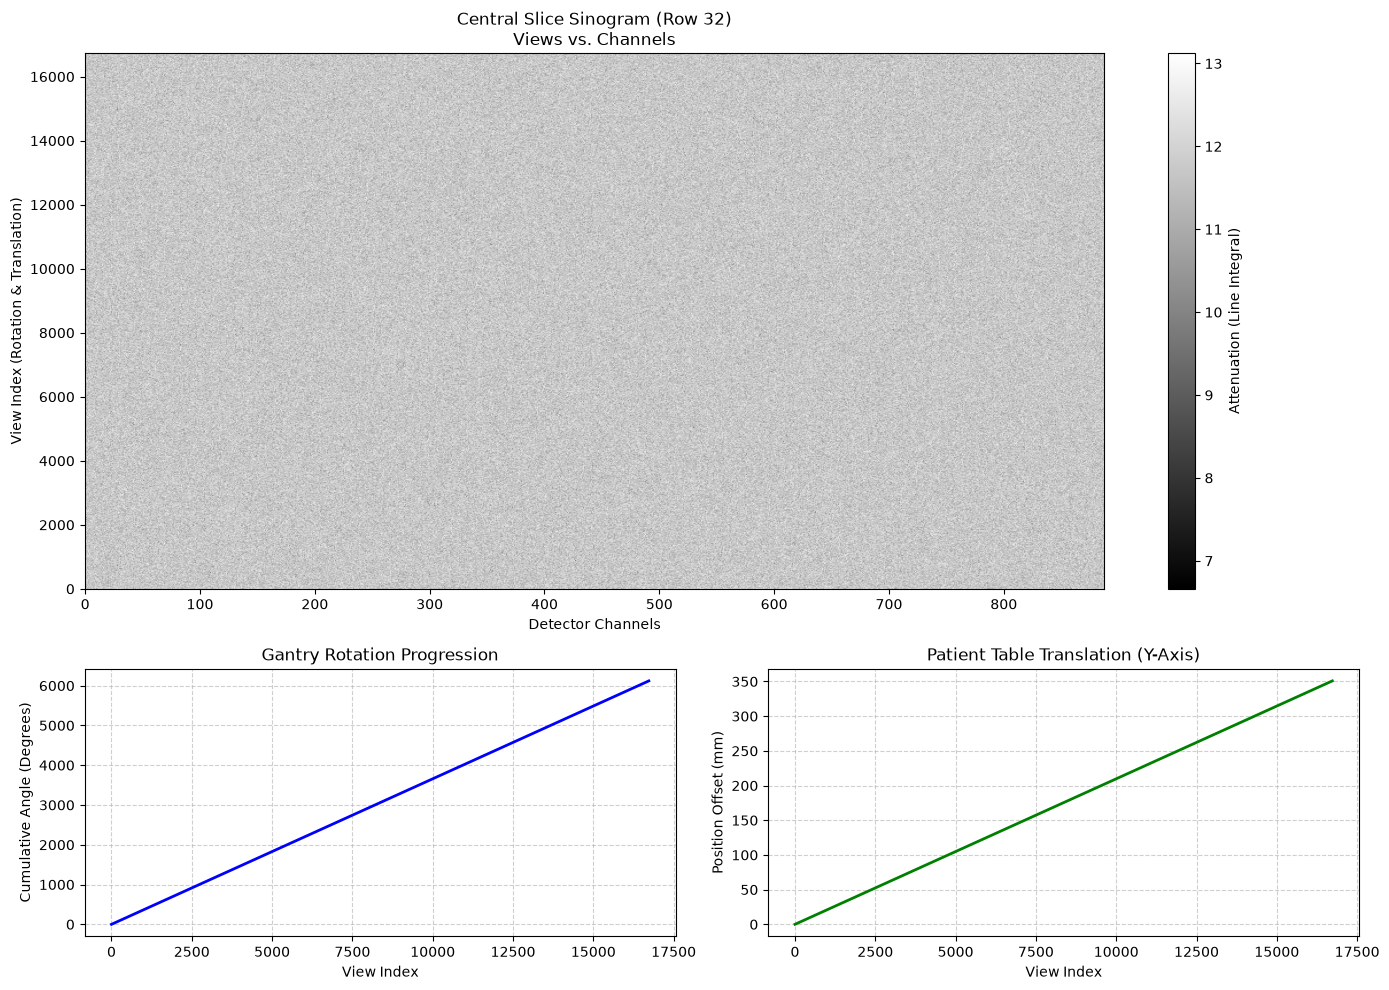